# Seuil de déclenchement sur le FWI Copernicus (G2, décision 008)

**But :** pour chaque seuil de FWI, mesurer ce que coûterait le dispositif renforcé et les deux erreurs, sur les feux réels du 77 :
- **coût** : nombre de jours de déclenchement par an ;
- **alertes sans feu** : part des jours de déclenchement où aucun feu n'est parti ;
- **feux sans alerte** : part des feux partis un jour où le dispositif n'était pas déclenché.

**Règles fixées avant de regarder les résultats (décision 008) :**
- seuils candidats : les bornes EFFIS présentes dans le 77, **11,2** (début de « modéré ») et **21,3** (début d'« élevé ») ;
- les autres valeurs sont montrées **pour information seulement** ;
- un feu = une fiche BDIFF (décision 006).

**Période :** 2024 et 2025, **toute l'année** (Copernicus existe aussi hors juin-septembre). Le notebook sera relancé sur 2016-2025 quand Daryl aura déposé 2016-2023 (#46).

## 1. Chargement

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BRONZE = Path('..') / 'data' / 'bronze'
ANNEES = [2024, 2025]          # années où l'on a à la fois Copernicus et la BDIFF
SEUILS_EFFIS = [11.2, 21.3]    # candidats fixés d'avance
FONTAINEBLEAU = (48.404, 2.701)  # latitude, longitude de la ville

### Copernicus : la valeur du 77 et le point le plus proche de Fontainebleau

- `copernicus_AAAA_idf_dept_jour.csv` : une valeur par département et par jour (moyenne des points de la grille, méthode de Daryl) ;
- `copernicus_AAAA_77.csv` : les 6 points de la grille situés dans le 77, avec leur position.

In [2]:
dept = pd.concat([pd.read_csv(BRONZE / 'copernicus' / f'copernicus_{a}_idf_dept_jour.csv', dtype={'code_departement': str})
                  for a in ANNEES], ignore_index=True)
fwi77 = dept[dept['code_departement'] == '77'][['time', 'fwinx']].rename(columns={'time': 'jour', 'fwinx': 'fwi_moyenne_77'})

points = pd.concat([pd.read_csv(BRONZE / 'copernicus' / f'copernicus_{a}_77.csv') for a in ANNEES], ignore_index=True)
# Les coordonnées n'ont pas exactement les mêmes décimales d'une année à l'autre : on arrondit pour reconnaître le même point
points['latitude'] = points['latitude'].round(3)
points['longitude'] = points['longitude'].round(3)
grille = points[['latitude', 'longitude', 'commune_77']].drop_duplicates()
grille['distance_km'] = np.hypot((grille['latitude'] - FONTAINEBLEAU[0]) * 111,
                                 (grille['longitude'] - FONTAINEBLEAU[1]) * 111 * np.cos(np.radians(FONTAINEBLEAU[0])))
grille.sort_values('distance_km')

,latitude,longitude,commune_77,distance_km
3,48.478,2.800,Féricy,10.985962
5,48.197,2.800,Chaintreaux,24.107345
4,48.478,3.200,Paroy,37.677574
1,48.759,2.800,Neufmoutiers-en-Brie,40.074625
2,48.759,3.200,Choisy-en-Brie,53.896974
0,49.040,2.917,Étrépilly,72.368139


In [3]:
proche = grille.sort_values('distance_km').iloc[0]
print(f"Point retenu pour Fontainebleau : {proche['commune_77']} ({proche['distance_km']:.0f} km de Fontainebleau)")

fwi_fb = (points[(points['latitude'] == proche['latitude']) & (points['longitude'] == proche['longitude'])]
          [['time', 'fwinx']].rename(columns={'time': 'jour', 'fwinx': 'fwi_fontainebleau'}))
fwi = fwi77.merge(fwi_fb, on='jour')
fwi['jour'] = pd.to_datetime(fwi['jour'])
print(fwi.shape)
fwi.describe().round(1)

Point retenu pour Fontainebleau : Féricy (11 km de Fontainebleau)
(731, 3)


,jour,fwi_moyenne_77,fwi_fontainebleau
count,731,731.0,731.0
mean,2024-12-31 00:00:00,4.2,4.3
min,2024-01-01 00:00:00,0.0,0.0
25%,2024-07-01 12:00:00,0.2,0.2
50%,2024-12-31 00:00:00,1.0,0.8
75%,2025-07-01 12:00:00,5.8,6.1
max,2025-12-31 00:00:00,35.5,37.6
std,NaN,6.2,6.5


### BDIFF : les feux du 77, jour par jour

In [4]:
def lire_bdiff(chemin):
    lignes = chemin.read_text(encoding='utf-8-sig').splitlines()
    entete = next(n for n, l in enumerate(lignes) if l.startswith('Année;'))
    return pd.read_csv(chemin, sep=';', skiprows=entete, dtype=str)

bdiff = lire_bdiff(BRONZE / 'bdiff' / 'Incendies_2016_2025.csv')
f77 = bdiff[(bdiff['Département'] == '77') & bdiff['Année'].isin([str(a) for a in ANNEES])].copy()
f77['jour'] = pd.to_datetime(f77['Date de première alerte']).dt.normalize()
feux_par_jour = f77.groupby('jour').size().rename('nb_feux')
print('Feux du 77 en', ANNEES, ':', len(f77))

Feux du 77 en [2024, 2025] : 65


## 2. La table « un jour » pour le 77

In [5]:
t = fwi.merge(feux_par_jour, on='jour', how='left')
t['nb_feux'] = t['nb_feux'].fillna(0).astype(int)
t['jour_avec_feu'] = t['nb_feux'] > 0

# Contrôle : chaque feu doit tomber sur un jour de la table (Copernicus couvre toute l'année)
print('Jours :', len(t), '| feux rattachés :', t['nb_feux'].sum(), '/', len(f77),
      '→', 'OK' if t['nb_feux'].sum() == len(f77) else 'ÉCART À EXPLIQUER')
t.head()

Jours : 731 | feux rattachés : 65 / 65 → OK


,jour,fwi_moyenne_77,fwi_fontainebleau,nb_feux,jour_avec_feu
0,2024-01-01,0.895833,0.875000,1,True
1,2024-01-02,0.026042,0.027344,0,False
2,2024-01-03,0.148438,0.199219,0,False
3,2024-01-04,0.197917,0.281250,0,False
4,2024-01-05,0.307292,0.384766,0,False


## 3. Le tableau des seuils

Pour chaque seuil, on « déclenche » les jours où le FWI est au moins égal au seuil.

In [6]:
def evaluer(fwi_col, seuils):
    nb_annees = len(ANNEES)
    total_feux = t['nb_feux'].sum()
    lignes = []
    for s in seuils:
        alerte = t[fwi_col] >= s
        jours_alerte = int(alerte.sum())
        lignes.append({
            'seuil FWI': s,
            'candidat EFFIS': 'oui' if s in SEUILS_EFFIS else '',
            'jours de déclenchement par an': round(jours_alerte / nb_annees, 1),
            'alertes sans feu %': round(100 * (alerte & ~t['jour_avec_feu']).sum() / jours_alerte, 1) if jours_alerte else None,
            'feux couverts': int(t.loc[alerte, 'nb_feux'].sum()),
            'feux sans alerte %': round(100 * t.loc[~alerte, 'nb_feux'].sum() / total_feux, 1),
        })
    return pd.DataFrame(lignes).set_index('seuil FWI')

seuils = sorted(set(SEUILS_EFFIS) | {5, 8, 14, 17, 25, 30})
print('Valeur du 77 = moyenne des 6 points')
evaluer('fwi_moyenne_77', seuils)

Valeur du 77 = moyenne des 6 points


,candidat EFFIS,jours de déclenchement par an,alertes sans feu %,feux couverts,feux sans alerte %
seuil FWI,,,,,
5.0,,101.5,79.8,50,23.1
8.0,,73.0,75.3,45,30.8
11.2,oui,48.5,73.2,32,50.8
14.0,,32.5,72.3,22,66.2
17.0,,20.5,70.7,16,75.4
21.3,oui,11.0,72.7,10,84.6
25.0,,5.0,70.0,4,93.8
30.0,,2.0,75.0,2,96.9


In [7]:
print('Valeur du 77 = point le plus proche de Fontainebleau')
evaluer('fwi_fontainebleau', seuils)

Valeur du 77 = point le plus proche de Fontainebleau


,candidat EFFIS,jours de déclenchement par an,alertes sans feu %,feux couverts,feux sans alerte %
seuil FWI,,,,,
5.0,,100.5,79.6,50,23.1
8.0,,72.5,77.9,40,38.5
11.2,oui,52.0,75.0,32,50.8
14.0,,35.5,73.2,23,64.6
17.0,,23.0,71.7,17,73.8
21.3,oui,13.5,63.0,14,78.5
25.0,,6.5,69.2,6,90.8
30.0,,2.5,60.0,3,95.4


## 4. Le compromis coût / feux couverts

Chaque courbe montre, pour tous les seuils de 0 à 35, le nombre de jours de déclenchement par an (coût) et la part des feux couverts. Les candidats EFFIS sont marqués.

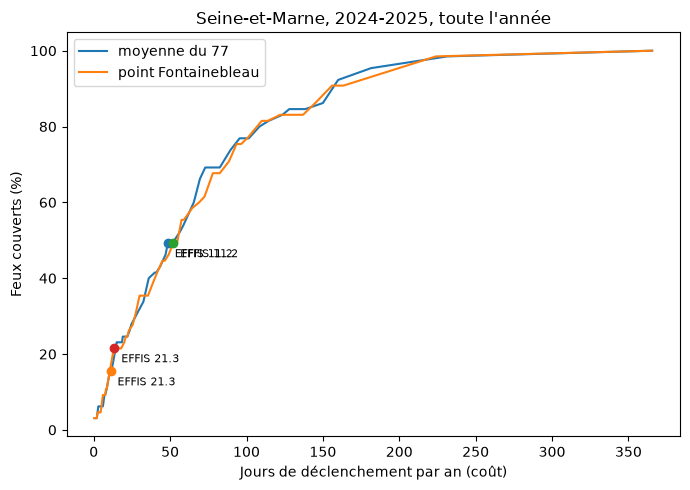

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
grille_seuils = sorted(set(np.round(np.arange(0, 35.5, 0.5), 1)) | set(SEUILS_EFFIS))
for col, nom in [('fwi_moyenne_77', 'moyenne du 77'), ('fwi_fontainebleau', 'point Fontainebleau')]:
    r = evaluer(col, grille_seuils)
    couvert = 100 - r['feux sans alerte %']
    ax.plot(r['jours de déclenchement par an'], couvert, label=nom)
    for s in SEUILS_EFFIS:
        ax.scatter(r.loc[s, 'jours de déclenchement par an'], 100 - r.loc[s, 'feux sans alerte %'], zorder=3)
        ax.annotate(f'EFFIS {s}', (r.loc[s, 'jours de déclenchement par an'], 100 - r.loc[s, 'feux sans alerte %']),
                    textcoords='offset points', xytext=(5, -10), fontsize=8)
ax.set_xlabel('Jours de déclenchement par an (coût)')
ax.set_ylabel('Feux couverts (%)')
ax.set_title('Seine-et-Marne, 2024-2025, toute l\'année')
ax.legend()
plt.tight_layout()

## 5. Le menu par budget

Pour chaque budget (en jours de dispositif renforcé par an), le seuil de FWI le plus bas qui reste dans ce budget, et ce qu'il aurait donné sur 2024-2025. Valeur utilisée : le point le plus proche de Fontainebleau (meilleure que la moyenne du 77 au seuil élevé, section 3).

À comparer avec la Météo des forêts : le niveau 2 a été atteint 22 jours sur 2024-2025 (11 par an, juin-septembre seulement) et aurait couvert 10 feux sur 65 (notebook 01).

In [9]:
def menu(fwi_col, budgets):
    nb_annees = len(ANNEES)
    total_feux = t['nb_feux'].sum()
    candidats = np.round(np.arange(0, 40.05, 0.1), 1)
    lignes = []
    for b in budgets:
        # le seuil le plus bas dont le nombre de jours par an tient dans le budget
        seuil = next(s for s in candidats if (t[fwi_col] >= s).sum() / nb_annees <= b)
        alerte = t[fwi_col] >= seuil
        jours = int(alerte.sum())
        lignes.append({
            'budget (jours par an)': b,
            'seuil FWI': seuil,
            'jours réels par an': round(jours / nb_annees, 1),
            'feux couverts': f"{int(t.loc[alerte, 'nb_feux'].sum())} sur {total_feux}",
            'feux couverts %': round(100 * t.loc[alerte, 'nb_feux'].sum() / total_feux, 1),
            'jours payés pour rien %': round(100 * (alerte & ~t['jour_avec_feu']).sum() / jours, 1) if jours else None,
        })
    return pd.DataFrame(lignes).set_index('budget (jours par an)')

menu('fwi_fontainebleau', [5, 10, 15, 25, 50, 75])

,seuil FWI,jours réels par an,feux couverts,feux couverts %,jours payés pour rien %
budget (jours par an),,,,,
5,25.9,5.0,3 sur 65,4.6,80.0
10,22.4,9.0,7 sur 65,10.8,72.2
15,20.9,14.5,14 sur 65,21.5,65.5
25,16.8,25.0,18 sur 65,27.7,72.0
50,11.5,49.0,30 sur 65,46.2,74.5
75,7.8,74.0,42 sur 65,64.6,77.0


## 6. Et les feux de printemps ?

La Météo des forêts n'existe pas d'avril à mai. Le FWI, si : les feux de printemps auraient-ils été couverts ?

In [10]:
t['mois'] = t['jour'].dt.month
lignes = []
for s in SEUILS_EFFIS:
    for col in ['fwi_moyenne_77', 'fwi_fontainebleau']:
        printemps = t['mois'].between(3, 5)
        feux_p = t.loc[printemps, 'nb_feux'].sum()
        couverts = t.loc[printemps & (t[col] >= s), 'nb_feux'].sum()
        lignes.append({'seuil': s, 'valeur': col, 'feux mars-mai': int(feux_p), 'couverts': int(couverts),
                       'part couverte %': round(100 * couverts / feux_p, 1) if feux_p else None})
pd.DataFrame(lignes)

,seuil,valeur,feux mars-mai,couverts,part couverte %
0,11.2,fwi_moyenne_77,21,8,38.1
1,11.2,fwi_fontainebleau,21,10,47.6
2,21.3,fwi_moyenne_77,21,1,4.8
3,21.3,fwi_fontainebleau,21,2,9.5


## 7. Ce qu'on retient

À compléter après lecture des résultats :
- …

**Limites :**
- deux années seulement (2024 très calme, 2025 très active) : à relancer sur 2016-2025 (#46), avec calage sur 2016-2022 et test sur 2023-2025 ;
- le FWI Copernicus est une **reconstitution après coup**, sur des points espacés d'environ 30 km. Le SDIS, lui, décide la veille sur une **prévision** : un seuil Copernicus ne se transpose pas tel quel dans l'IFM opérationnel de Météo-France ;
- le FWI mesure le danger **météorologique** : 9 feux sur 10 sont d'origine humaine, un FWI bas n'empêche pas un départ de feu ;
- un jour d'alerte sans feu peut être un jour où le dispositif a **empêché** un feu (risque résiduel de la fiche G2).